A/B Testing For an E-Commerce Website Ad Marketing

A/B testing means to analyse two marketing strategies in order to choose the best one that can convert more traffic into sales (or a desired goal) effectively and efficiently.

A/B testing helps in finding a better approach to finding customers, marketing products, getting a higher reach, or anything that helps a business convert most of its target customers into actual customers.

The Project

In this project, I will be performing an A/B test on two different ad strategies for an E-Commerce company and try to understand the results obtained from it. The company performed two different campaigns:

Control Campaign
Test Campaign
The goal is to help the company decide if they should implement the new ad marketing or stick to the old one in order to get more customers.

The datasets used has been collected from Kaggle and has been submitted by İlker Yıldız. Please note that the use case of the dataset has been changed from its original for the purpose of this project.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
control_data = pd.read_csv(r"C:\Users\DELL\Downloads\control_group.csv", sep = ';')
control_data

,Campaign Name,Date,Spend [USD],# of Impressions,Reach,# of Website Clicks,# of Searches,# of View Content,# of Add to Cart,# of Purchase
0,Control Campaign,1.08.2019,2280,82702.0,56930.0,7016.0,2290.0,2159.0,1819.0,618.0
1,Control Campaign,2.08.2019,1757,121040.0,102513.0,8110.0,2033.0,1841.0,1219.0,511.0
2,Control Campaign,3.08.2019,2343,131711.0,110862.0,6508.0,1737.0,1549.0,1134.0,372.0
3,Control Campaign,4.08.2019,1940,72878.0,61235.0,3065.0,1042.0,982.0,1183.0,340.0
4,Control Campaign,5.08.2019,1835,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Control Campaign,6.08.2019,3083,109076.0,87998.0,4028.0,1709.0,1249.0,784.0,764.0
6,Control Campaign,7.08.2019,2544,142123.0,127852.0,2640.0,1388.0,1106.0,1166.0,499.0
7,Control Campaign,8.08.2019,1900,90939.0,65217.0,7260.0,3047.0,2746.0,930.0,462.0
8,Control Campaign,9.08.2019,2813,121332.0,94896.0,6198.0,2487.0,2179.0,645.0,501.0
9,Control Campaign,10.08.2019,2149,117624.0,91257.0,2277.0,2475.0,1984.0,1629.0,734.0


In [4]:
test_data = pd.read_csv(r"C:\Users\DELL\Downloads\test_group.csv", sep = ';')
test_data

,Campaign Name,Date,Spend [USD],# of Impressions,Reach,# of Website Clicks,# of Searches,# of View Content,# of Add to Cart,# of Purchase
0,Test Campaign,1.08.2019,3008,39550,35820,3038,1946,1069,894,255
1,Test Campaign,2.08.2019,2542,100719,91236,4657,2359,1548,879,677
2,Test Campaign,3.08.2019,2365,70263,45198,7885,2572,2367,1268,578
3,Test Campaign,4.08.2019,2710,78451,25937,4216,2216,1437,566,340
4,Test Campaign,5.08.2019,2297,114295,95138,5863,2106,858,956,768
5,Test Campaign,6.08.2019,2458,42684,31489,7488,1854,1073,882,488
6,Test Campaign,7.08.2019,2838,53986,42148,4221,2733,2182,1301,890
7,Test Campaign,8.08.2019,2916,33669,20149,7184,2867,2194,1240,431
8,Test Campaign,9.08.2019,2652,45511,31598,8259,2899,2761,1200,845
9,Test Campaign,10.08.2019,2790,95054,79632,8125,2312,1804,424,275


Assessing the Datasets

In [5]:
print(f'Control Data Shape :{control_data.shape}\nTest Data Shape : {test_data.shape}')

Control Data Shape :(30, 10)
Test Data Shape : (30, 10)


In [6]:
control_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Campaign Name        30 non-null     object 
 1   Date                 30 non-null     object 
 2   Spend [USD]          30 non-null     int64  
 3   # of Impressions     29 non-null     float64
 4   Reach                29 non-null     float64
 5   # of Website Clicks  29 non-null     float64
 6   # of Searches        29 non-null     float64
 7   # of View Content    29 non-null     float64
 8   # of Add to Cart     29 non-null     float64
 9   # of Purchase        29 non-null     float64
dtypes: float64(7), int64(1), object(2)
memory usage: 2.5+ KB


In [7]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Campaign Name        30 non-null     object
 1   Date                 30 non-null     object
 2   Spend [USD]          30 non-null     int64 
 3   # of Impressions     30 non-null     int64 
 4   Reach                30 non-null     int64 
 5   # of Website Clicks  30 non-null     int64 
 6   # of Searches        30 non-null     int64 
 7   # of View Content    30 non-null     int64 
 8   # of Add to Cart     30 non-null     int64 
 9   # of Purchase        30 non-null     int64 
dtypes: int64(8), object(2)
memory usage: 2.5+ KB


In [8]:
## fixing column names:
column_names = ['campaign', 'date', 'spend_usd', 'impressions', 'reach', 'website_clicks', 'searches', 'view_content', 'add_to_cart', 'purchase']

In [9]:
control_data.columns = column_names
test_data.columns = column_names

In [10]:
control_data.head()

,campaign,date,spend_usd,impressions,reach,website_clicks,searches,view_content,add_to_cart,purchase
0,Control Campaign,1.08.2019,2280,82702.0,56930.0,7016.0,2290.0,2159.0,1819.0,618.0
1,Control Campaign,2.08.2019,1757,121040.0,102513.0,8110.0,2033.0,1841.0,1219.0,511.0
2,Control Campaign,3.08.2019,2343,131711.0,110862.0,6508.0,1737.0,1549.0,1134.0,372.0
3,Control Campaign,4.08.2019,1940,72878.0,61235.0,3065.0,1042.0,982.0,1183.0,340.0
4,Control Campaign,5.08.2019,1835,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
test_data.head()

,campaign,date,spend_usd,impressions,reach,website_clicks,searches,view_content,add_to_cart,purchase
0,Test Campaign,1.08.2019,3008,39550,35820,3038,1946,1069,894,255
1,Test Campaign,2.08.2019,2542,100719,91236,4657,2359,1548,879,677
2,Test Campaign,3.08.2019,2365,70263,45198,7885,2572,2367,1268,578
3,Test Campaign,4.08.2019,2710,78451,25937,4216,2216,1437,566,340
4,Test Campaign,5.08.2019,2297,114295,95138,5863,2106,858,956,768


In [12]:
## checking duplicates

control_data.duplicated().sum()

0

In [13]:
test_data.duplicated().sum()

0

In [14]:
## check the columns with null values
control_data.isnull().sum()

campaign          0
date              0
spend_usd         0
impressions       1
reach             1
website_clicks    1
searches          1
view_content      1
add_to_cart       1
purchase          1
dtype: int64

In [15]:
null_columns = ['impressions','reach','website_clicks','searches','view_content','add_to_cart','purchase']
for col in null_columns:
    control_data[col].fillna(value= control_data[col].mean(), inplace= True)

In [16]:
control_data.isnull().sum()

campaign          0
date              0
spend_usd         0
impressions       0
reach             0
website_clicks    0
searches          0
view_content      0
add_to_cart       0
purchase          0
dtype: int64

Merging the Datasets

In [17]:
##full outer join
merged_data = control_data.merge(test_data, how= 'outer')
merged_data

C:\Users\DELL\AppData\Local\Temp\ipykernel_11360\659240736.py:2: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  merged_data = control_data.merge(test_data, how= 'outer')


,campaign,date,spend_usd,impressions,reach,website_clicks,searches,view_content,add_to_cart,purchase
0,Control Campaign,1.08.2019,2280,82702.000000,56930.000000,7016.000000,2290.000000,2159.000000,1819.0,618.000000
1,Control Campaign,2.08.2019,1757,121040.000000,102513.000000,8110.000000,2033.000000,1841.000000,1219.0,511.000000
2,Control Campaign,3.08.2019,2343,131711.000000,110862.000000,6508.000000,1737.000000,1549.000000,1134.0,372.000000
3,Control Campaign,4.08.2019,1940,72878.000000,61235.000000,3065.000000,1042.000000,982.000000,1183.0,340.000000
4,Control Campaign,5.08.2019,1835,109559.758621,88844.931034,5320.793103,2221.310345,1943.793103,1300.0,522.793103
5,Control Campaign,6.08.2019,3083,109076.000000,87998.000000,4028.000000,1709.000000,1249.000000,784.0,764.000000
6,Control Campaign,7.08.2019,2544,142123.000000,127852.000000,2640.000000,1388.000000,1106.000000,1166.0,499.000000
7,Control Campaign,8.08.2019,1900,90939.000000,65217.000000,7260.000000,3047.000000,2746.000000,930.0,462.000000
8,Control Campaign,9.08.2019,2813,121332.000000,94896.000000,6198.000000,2487.000000,2179.000000,645.0,501.000000
9,Control Campaign,10.08.2019,2149,117624.000000,91257.000000,2277.000000,2475.000000,1984.000000,1629.0,734.000000


In [18]:
merged_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   campaign        60 non-null     object 
 1   date            60 non-null     object 
 2   spend_usd       60 non-null     int64  
 3   impressions     60 non-null     float64
 4   reach           60 non-null     float64
 5   website_clicks  60 non-null     float64
 6   searches        60 non-null     float64
 7   view_content    60 non-null     float64
 8   add_to_cart     60 non-null     float64
 9   purchase        60 non-null     float64
dtypes: float64(7), int64(1), object(2)
memory usage: 4.8+ KB


In [19]:
##convert date column to datatime
merged_data['date']= pd.to_datetime(merged_data['date'],dayfirst = True)
merged_data

,campaign,date,spend_usd,impressions,reach,website_clicks,searches,view_content,add_to_cart,purchase
0,Control Campaign,2019-08-01,2280,82702.000000,56930.000000,7016.000000,2290.000000,2159.000000,1819.0,618.000000
1,Control Campaign,2019-08-02,1757,121040.000000,102513.000000,8110.000000,2033.000000,1841.000000,1219.0,511.000000
2,Control Campaign,2019-08-03,2343,131711.000000,110862.000000,6508.000000,1737.000000,1549.000000,1134.0,372.000000
3,Control Campaign,2019-08-04,1940,72878.000000,61235.000000,3065.000000,1042.000000,982.000000,1183.0,340.000000
4,Control Campaign,2019-08-05,1835,109559.758621,88844.931034,5320.793103,2221.310345,1943.793103,1300.0,522.793103
5,Control Campaign,2019-08-06,3083,109076.000000,87998.000000,4028.000000,1709.000000,1249.000000,784.0,764.000000
6,Control Campaign,2019-08-07,2544,142123.000000,127852.000000,2640.000000,1388.000000,1106.000000,1166.0,499.000000
7,Control Campaign,2019-08-08,1900,90939.000000,65217.000000,7260.000000,3047.000000,2746.000000,930.0,462.000000
8,Control Campaign,2019-08-09,2813,121332.000000,94896.000000,6198.000000,2487.000000,2179.000000,645.0,501.000000
9,Control Campaign,2019-08-10,2149,117624.000000,91257.000000,2277.000000,2475.000000,1984.000000,1629.0,734.000000


In [20]:
##sort by date
merged_data = merged_data.sort_values(by = ['date'])

In [21]:
## reset index
merged_data = merged_data.reset_index(drop = True)

In [22]:
merged_data

,campaign,date,spend_usd,impressions,reach,website_clicks,searches,view_content,add_to_cart,purchase
0,Control Campaign,2019-08-01,2280,82702.000000,56930.000000,7016.000000,2290.000000,2159.000000,1819.0,618.000000
1,Test Campaign,2019-08-01,3008,39550.000000,35820.000000,3038.000000,1946.000000,1069.000000,894.0,255.000000
2,Control Campaign,2019-08-02,1757,121040.000000,102513.000000,8110.000000,2033.000000,1841.000000,1219.0,511.000000
3,Test Campaign,2019-08-02,2542,100719.000000,91236.000000,4657.000000,2359.000000,1548.000000,879.0,677.000000
4,Control Campaign,2019-08-03,2343,131711.000000,110862.000000,6508.000000,1737.000000,1549.000000,1134.0,372.000000
5,Test Campaign,2019-08-03,2365,70263.000000,45198.000000,7885.000000,2572.000000,2367.000000,1268.0,578.000000
6,Control Campaign,2019-08-04,1940,72878.000000,61235.000000,3065.000000,1042.000000,982.000000,1183.0,340.000000
7,Test Campaign,2019-08-04,2710,78451.000000,25937.000000,4216.000000,2216.000000,1437.000000,566.0,340.000000
8,Control Campaign,2019-08-05,1835,109559.758621,88844.931034,5320.793103,2221.310345,1943.793103,1300.0,522.793103
9,Test Campaign,2019-08-05,2297,114295.000000,95138.000000,5863.000000,2106.000000,858.000000,956.0,768.000000


EDA


In [23]:
## observation per campaign

merged_data.groupby(['campaign'])['campaign'].count()

campaign
Control Campaign    30
Test Campaign       30
Name: campaign, dtype: int64

In [24]:
reach_per_campaign = merged_data.groupby(['campaign'])['reach'].sum()
reach_per_campaign

campaign
Control Campaign    2.665348e+06
Test Campaign       1.604747e+06
Name: reach, dtype: float64

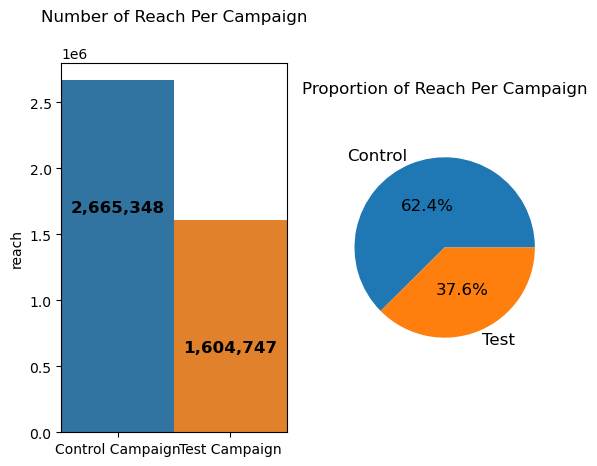

In [25]:
# plot the output
plt.subplot(1,2,1)
sns.barplot(x=reach_per_campaign.index, y=reach_per_campaign, width=1.00)

for i, val in enumerate(reach_per_campaign):
    plt.text(i, val - 1000000, "{:0,.0f}".format(val), fontsize=12, fontweight="bold", ha="center")

plt.xlabel('')
plt.title('Number of Reach Per Campaign', pad=30)

plt.subplot(1,2,2)
plt.pie(x=reach_per_campaign, autopct='%1.1f%%', textprops={'fontsize': 12}, labels=['Control', 'Test'], pctdistance=0.5)
plt.title('Proportion of Reach Per Campaign', pad=30)
plt.show()

It can now be seen that the number and proportion of reach in the control dataset is more than 1.5 times that in the test dataset. This is very likely to result in a bias while performing the A/B test.

Click Through Rate (CTR)

It can now be seen that the number and proportion of reach in the control dataset is more than 1.5 times that in the test dataset. This is very likely to result in a bias while performing the A/B test.

In [26]:
ctr = merged_data.groupby(['campaign'])['website_clicks'].sum() / merged_data.groupby(['campaign'])['reach'].sum() * 100
ctr

campaign
Control Campaign     5.988854
Test Campaign       11.277167
dtype: float64

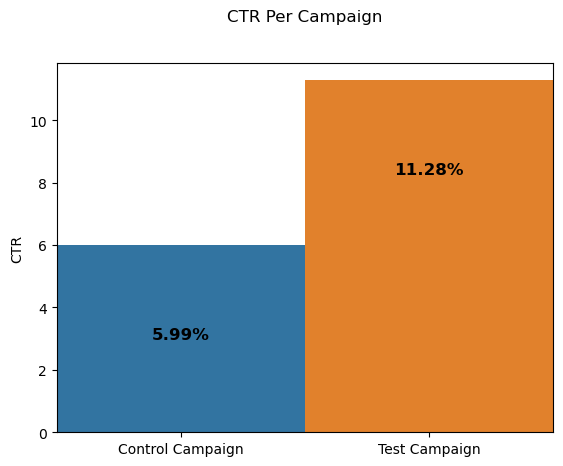

In [27]:
# plot the output
sns.barplot(x=ctr.index, y=ctr, width=1.00)

for i, val in enumerate(ctr):
    plt.text(i, val - 3, "{:.2f}%".format(val), fontsize=12, fontweight="bold", ha="center")

plt.xlabel('')
plt.ylabel('CTR')
plt.title('CTR Per Campaign', pad=30)
plt.show()

The above output shows an interesting insight of the dataset. Although previously, we had seen that the reach of the control campaign was significantly more than the test campaign, the click-through-rate of the latter is almost twice as much as the former campaign. It goes on to show that the conversion rate (in terms of website clicks) of the test campaign is much higher than the control campaign, although it fails to draw as many unique viewers.

Summary Statistics

To get an overall picture of each of the feature variables, let us create a summary statistics for the two campaigns. For this, I will be creating separate box plots for each of the columns which will not only give us the quartiles and extreme bounds, but will also allow us to compare the spread of the data for each campaign.



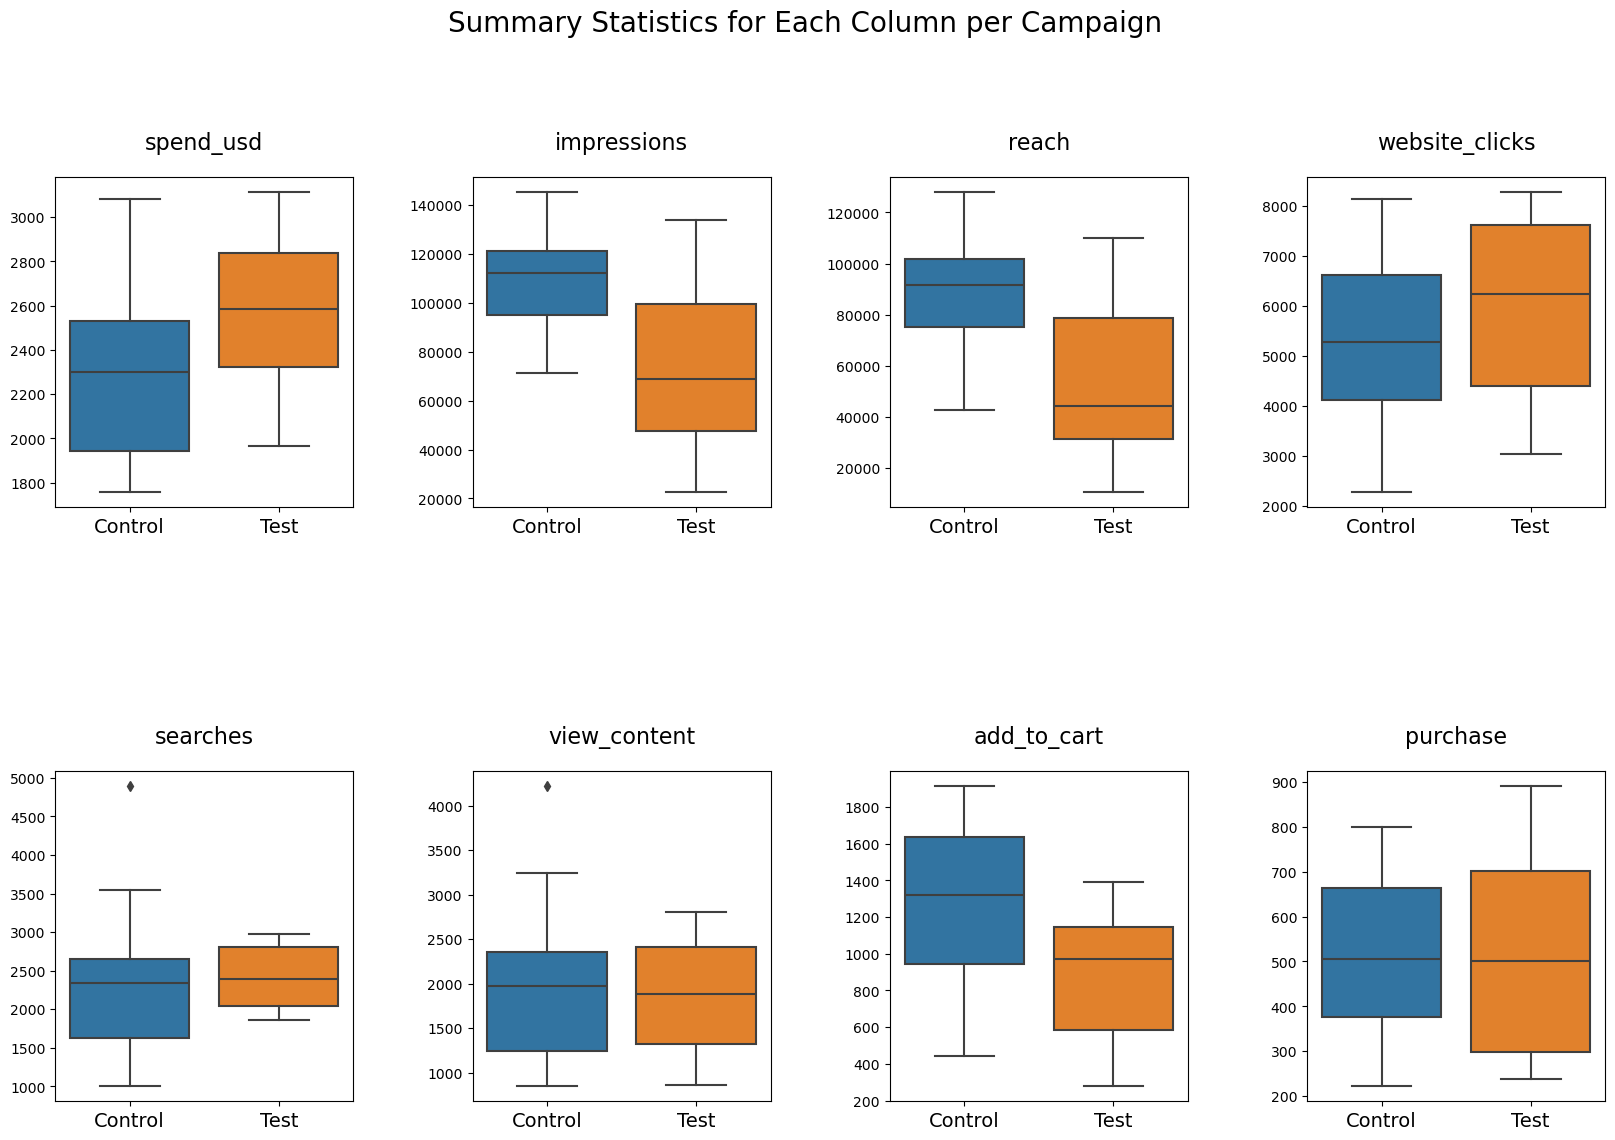

In [28]:
fig, ax = plt.subplots(2, 4, figsize=(20,12))

cols = merged_data.columns.values[2:10]

row, column = 0, 0

for col in cols:
    sns.boxplot(data=merged_data, x='campaign', y=col, ax=ax[row, column])
    ax[row, column].set_title(col, pad=20, fontsize=16)
    ax[row,column].set_xlabel('')
    ax[row,column].set_ylabel('')
    ax[row, column].set_xticklabels(labels=['Control', 'Test'], fontsize=14)

    # reset column and go to next row
    if column == 3:
        row+=1
        column=-1

    column+=1

plt.subplots_adjust(hspace=0.8, wspace=0.4)
plt.suptitle('Summary Statistics for Each Column per Campaign', y=1.02, fontsize=20)
plt.show()

Explanation:

spend_usd: It can be seen that the minimum amount of spending in the test campaign is greater than that of the control campaign. Same goes for the upper bound although to a much lesser extent. What is more interesting is that the control data is positively skewed meaning that more people tend to spend less here. It is more exaggerated by the fact that the median spend of the test campaign is more than the upper quartile of the control.

impressions: For this metric, we can see that the box plot of the control campaign is much higher and also narrower than that of the test campaign. This suggests that the control campaign saw a higher impression overall compared to its counterpart and also it is less spreaded.

reach: Similar to impressions, we can see that the minimum of unique observations in the control campaign is significantly greater than the minimum in the test, being close to the median of the latter. Also, the maximum reach of the control is also greater than test by about 10%.

website_clicks: Here we have an opposite scenario to the above observation, as the minimum number of clicks in the control group is smaller than the minimum in the test group by a difference of about 10%. Moreover, the median and upper bound of the test group is also more than that of the control, explaining why its CTR was greater.

searches: Although the minimum number of searches for the test group is greater than the 25% level of the number of research for the control, we find that the total spread of data for the control is much greater than the test. Also, note that there is an outlier beyond the upper bound in the control.

view_content: We find that the minimum and the first, second and third quartile levels of the view content numbers for both groups are very close, but the maximum for the control group was greater than the test with a difference of about 10%.

add_to_cart: We can see that the minimum number of people who added to cart in the control group is greater than the minimum in the test, and that the median value for the control is almost same as the maximum in test. Furthermore, the test data is positively skewed meaning that more people add fewer items in their carts.

purchase: Here the opposite happened a little. Although the minimum and median number of purchases in the two groups are almost close, 25% of the maximum number of purchases in the control group is greater than 25% in the test group. Also, the data for the test group is more spreaded meaning that people make a wider range of number of purchases in here.

Time Series Analysis:

For the last part of my EDA, I will be doing a time series comparison of the spend and CTR for the two groups.

In [29]:
## create ctr column 
merged_data['ctr'] = merged_data['website_clicks'] / merged_data['reach']
merged_data

,campaign,date,spend_usd,impressions,reach,website_clicks,searches,view_content,add_to_cart,purchase,ctr
0,Control Campaign,2019-08-01,2280,82702.000000,56930.000000,7016.000000,2290.000000,2159.000000,1819.0,618.000000,0.123239
1,Test Campaign,2019-08-01,3008,39550.000000,35820.000000,3038.000000,1946.000000,1069.000000,894.0,255.000000,0.084813
2,Control Campaign,2019-08-02,1757,121040.000000,102513.000000,8110.000000,2033.000000,1841.000000,1219.0,511.000000,0.079112
3,Test Campaign,2019-08-02,2542,100719.000000,91236.000000,4657.000000,2359.000000,1548.000000,879.0,677.000000,0.051043
4,Control Campaign,2019-08-03,2343,131711.000000,110862.000000,6508.000000,1737.000000,1549.000000,1134.0,372.000000,0.058704
5,Test Campaign,2019-08-03,2365,70263.000000,45198.000000,7885.000000,2572.000000,2367.000000,1268.0,578.000000,0.174455
6,Control Campaign,2019-08-04,1940,72878.000000,61235.000000,3065.000000,1042.000000,982.000000,1183.0,340.000000,0.050053
7,Test Campaign,2019-08-04,2710,78451.000000,25937.000000,4216.000000,2216.000000,1437.000000,566.0,340.000000,0.162548
8,Control Campaign,2019-08-05,1835,109559.758621,88844.931034,5320.793103,2221.310345,1943.793103,1300.0,522.793103,0.059889
9,Test Campaign,2019-08-05,2297,114295.000000,95138.000000,5863.000000,2106.000000,858.000000,956.0,768.000000,0.061626


C:\Users\DELL\python\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\DELL\python\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\DELL\python\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\DELL\python\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with

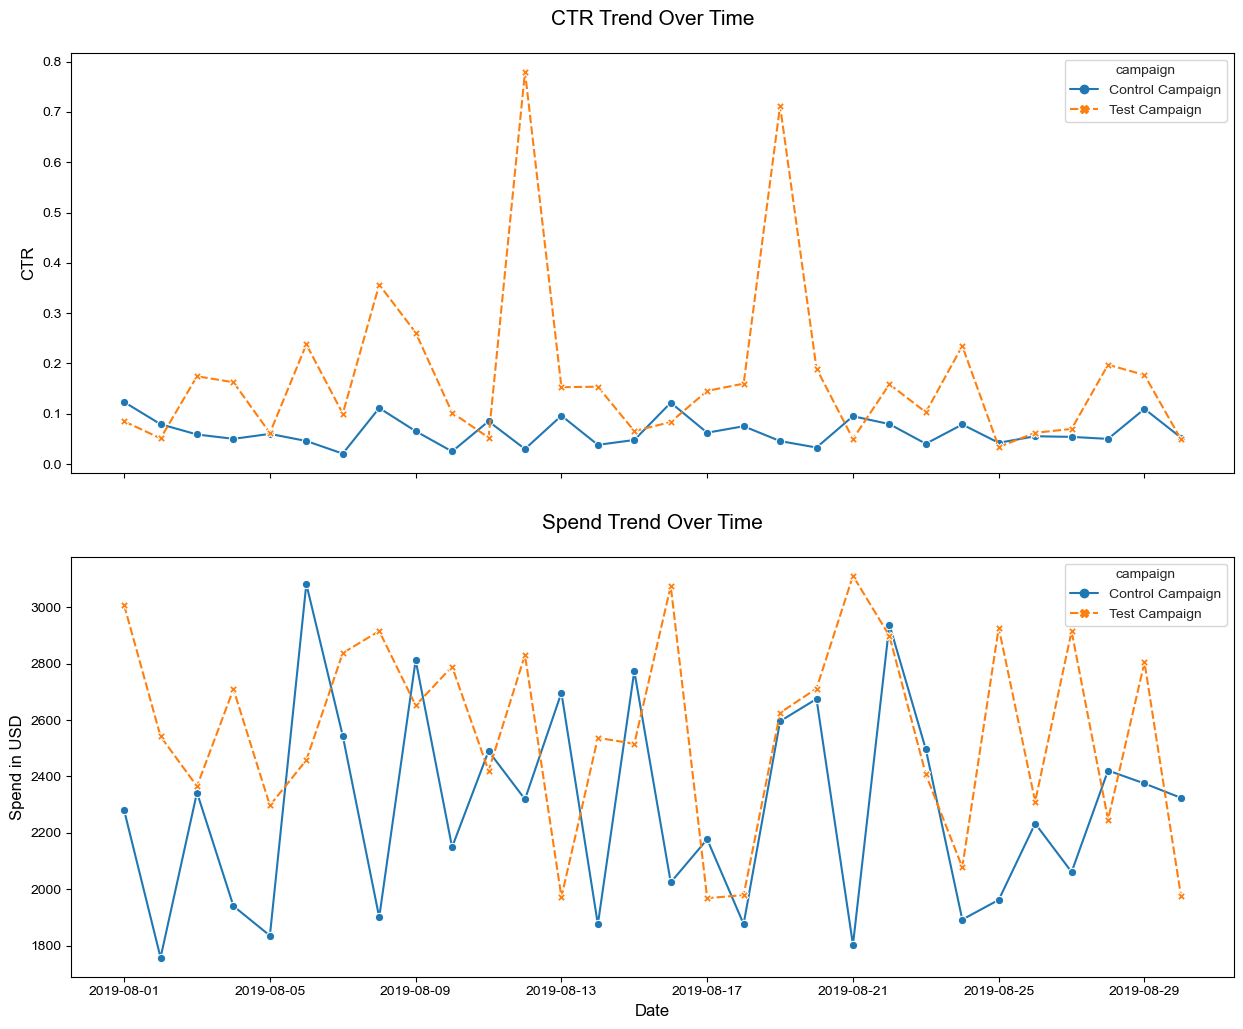

In [30]:
# plot ctr
fig, ax = plt.subplots(2, 1, figsize=(15, 12), sharex=True)
sns.set_style('whitegrid')
sns.lineplot(data=merged_data, x='date', y='ctr', hue='campaign', style='campaign', markers=True, ax=ax[0])
ax[0].set_ylabel('CTR', fontsize=12)
ax[0].set_xlabel('Date', fontsize=12)
ax[0].set_title('CTR Trend Over Time', fontsize=15, pad=20)

# plot spend
sns.lineplot(data=merged_data, x='date', y='spend_usd', hue='campaign', style='campaign', markers=True, ax=ax[1])
ax[1].set_ylabel('Spend in USD', fontsize=12)
ax[1].set_xlabel('Date', fontsize=12)
ax[1].set_title('Spend Trend Over Time', fontsize=15, pad=20)
plt.show()

As we can see from the graphs above, the CTR has clear effect on the total spend for the test campaign, with only a few anomalies. However, there is no clear connection between the CTR and spend in the control campaign. Hence, we cannot strongly say that there is a correlation between the two factors.

A/B Testing for the Best Strategy

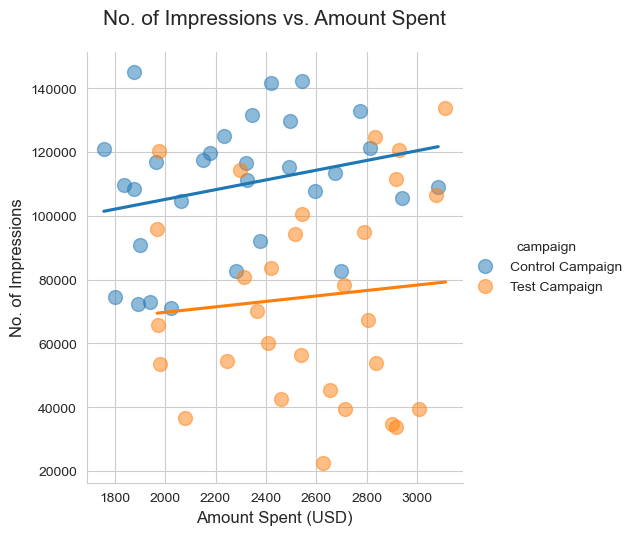

In [32]:
## amount spent vs impressions

sns.lmplot(data=merged_data, y='impressions', x='spend_usd', ci=None, hue='campaign', scatter_kws={'alpha': 0.5, 's': 100})
plt.ylabel('No. of Impressions', fontsize=12)
plt.xlabel('Amount Spent (USD)', fontsize=12)
plt.title('No. of Impressions vs. Amount Spent', fontsize=15, pad=20)
plt.show()

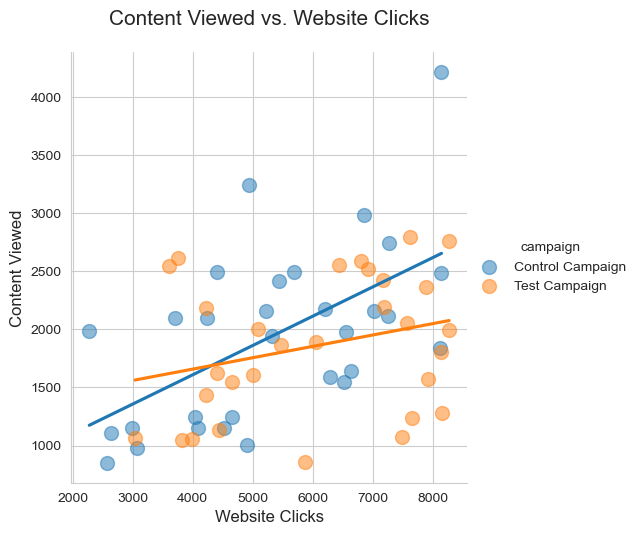

In [33]:
#content viewed vs website clicks

sns.lmplot(data=merged_data, y='view_content', x='website_clicks', ci=None, hue='campaign', scatter_kws={'alpha': 0.5, 's': 100})
plt.ylabel('Content Viewed', fontsize=12)
plt.xlabel('Website Clicks', fontsize=12)
plt.title('Content Viewed vs. Website Clicks', fontsize=15, pad=20)
plt.show()

As can be seen, although there are more website clicks in the test campaign, the engagement from the website clicks is higher in the control campaign. Hence, the control campaign wins in this aspect.

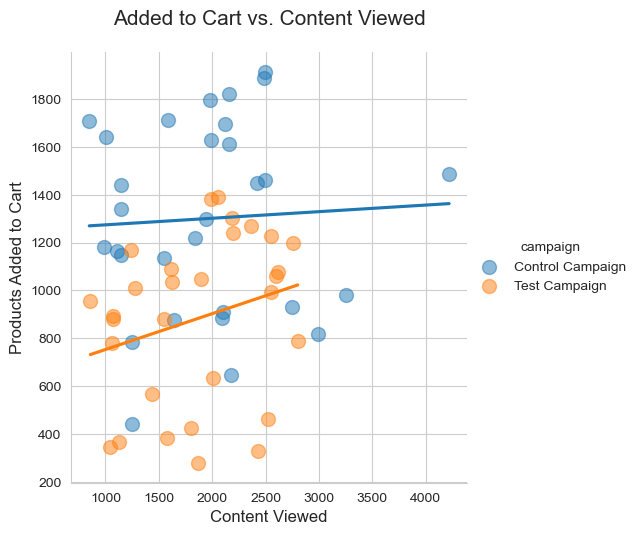

In [34]:
## added to cart vs content viewed
sns.lmplot(data=merged_data, x='view_content', y='add_to_cart', ci=None, hue='campaign', scatter_kws={'alpha': 0.5, 's': 100})
plt.xlabel('Content Viewed', fontsize=12)
plt.ylabel('Products Added to Cart', fontsize=12)
plt.title('Added to Cart vs. Content Viewed', fontsize=15, pad=20)
plt.show()

Here is another interesting graph. Although there were fewer people to add products to cart overall in the test campaign, the rate at which they were added with respect to the content viewed was more than that in the control campaign. This means that the more people view the content, more of them will add products to cart in the test campaign than in the control.

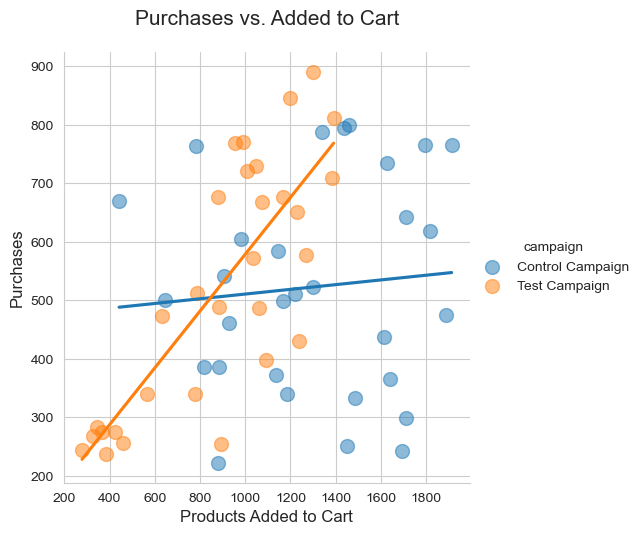

In [35]:
## purchase vs added to cart

sns.lmplot(data=merged_data, y='purchase', x='add_to_cart', ci=None, hue='campaign', scatter_kws={'alpha': 0.5, 's': 100})
plt.ylabel('Purchases', fontsize=12)
plt.xlabel('Products Added to Cart', fontsize=12)
plt.title('Purchases vs. Added to Cart', fontsize=15, pad=20)
plt.show()

Although the control campaign saw more people adding products to cart, most of them ended up purchasing the products in the test campaign, meaning their conversion rate was higher. This is more evident from the steeper regression line of the test campaign.

Searches Performed

Now that we have compared the conversion rates in the two campaigns using regression plots, we can turn our attention to comparing basic explicit metrics and see how their totals differ in the campaigns. For that, I will start by comparing the number of people performing searches on the website from both the campaigns.


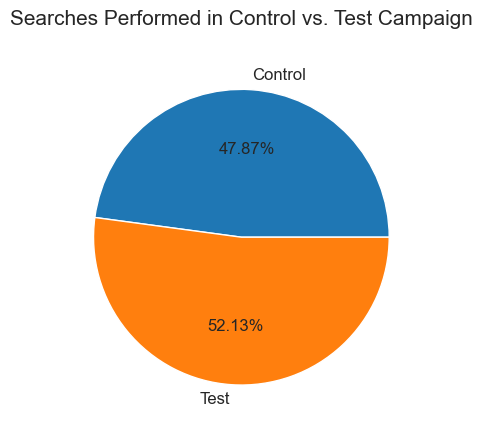

In [36]:
metric = [control_data['searches'].sum(), test_data['searches'].sum()]

plt.pie(metric, labels=['Control', 'Test'], autopct='%.2f%%', textprops={'fontsize': 12})
plt.title('Searches Performed in Control vs. Test Campaign', fontsize=15, pad=20)
plt.show()

Website clicks made

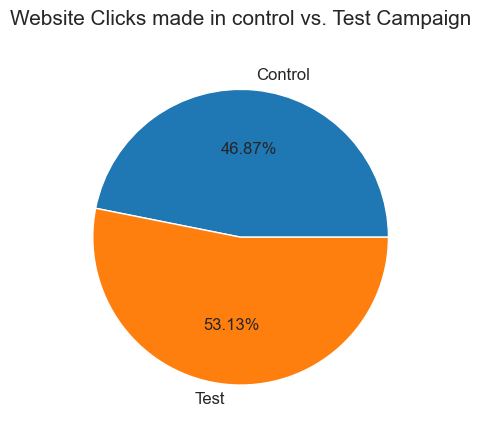

In [39]:
metric = [control_data['website_clicks'].sum(), test_data['website_clicks'].sum()]
plt.pie(metric, labels=['Control', 'Test'], autopct='%.2f%%', textprops={'fontsize': 12})
plt.title('Website Clicks made in control vs. Test Campaign', fontsize=15, pad=20)
plt.show()

Content Viewed

Now it is time to look at the number of people who viewed content after reaching the website landing page in both the campaigns and compare them.

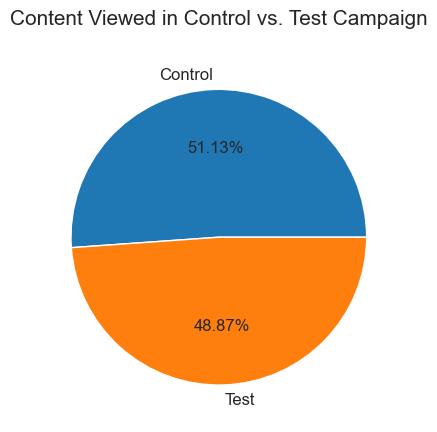

In [40]:
metric = [ control_data['view_content'].sum(), test_data['view_content'].sum()]

plt.pie(metric, labels=['Control', 'Test'], autopct='%.2f%%', textprops={'fontsize': 12})
plt.title('Content Viewed in Control vs. Test Campaign', fontsize=15, pad=20)
plt.show()

This time we can see that the number of people viewing content was more in control campaign than in the test campaign although the difference is not much.

Products added to Cart

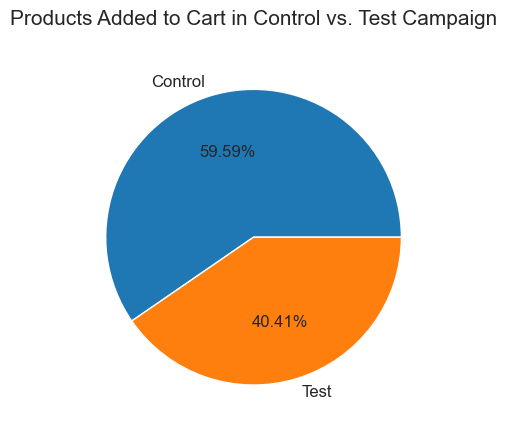

In [41]:
metric = [control_data['add_to_cart'].sum(), test_data['add_to_cart'].sum()]

plt.pie(metric, labels=['Control', 'Test'], autopct='%.2f%%', textprops={'fontsize': 12})
plt.title('Products Added to Cart in Control vs. Test Campaign', fontsize=15, pad=20)
plt.show()

The results do match my initial assumptions. With more people viewing content in the control campaign, more people added products to their carts than in the test campaign.

Amount of money spent

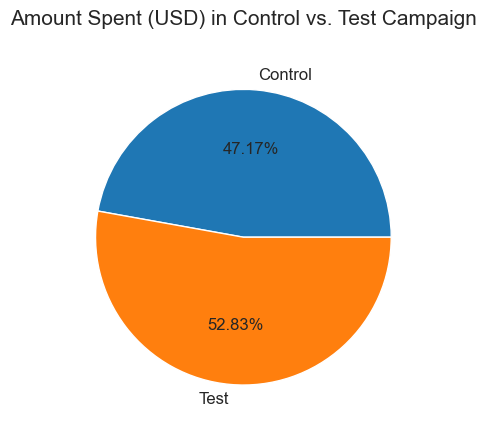

In [42]:
metric = [control_data['spend_usd'].sum(), test_data['spend_usd'].sum()]

plt.pie(metric, labels=['Control', 'Test'], autopct='%.2f%%', textprops={'fontsize': 12})
plt.title('Amount Spent (USD) in Control vs. Test Campaign', fontsize=15, pad=20)
plt.show()

From the pie chart it is evident that the amount spent on marketing in the test campaign was more than that spent in the control. However, since we have already seen more content views and added to cart in the control campaign with less expenditure than the test, the former is more efficient.

Purchases made


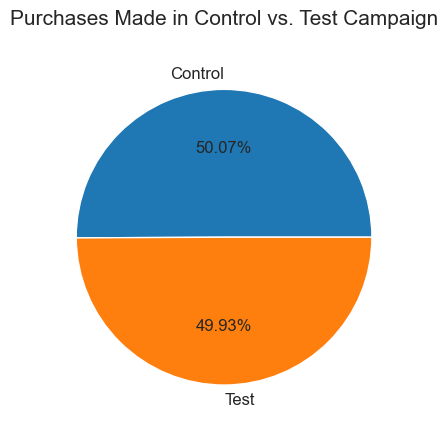

In [43]:
metric = [control_data['purchase'].sum(), test_data['purchase'].sum()]

plt.pie(metric, labels=['Control', 'Test'], autopct='%.2f%%', textprops={'fontsize': 12})
plt.title('Purchases Made in Control vs. Test Campaign', fontsize=15, pad=20)
plt.show()

Both the campaigns were neck and neck when it came to purchases, with a mere difference of 1%.

If we compare them on the basis of amount spent on marketing, then control campaign wins as it resulted in more sales in less amount spent.

However, if we compare them on the basis of conversion rate, then test wins as it produced almost similar number of purchases despite having significantly lesser number of people adding products to cart. This shows that people in the test campaign actually bought products that they added to cart instead of just keeping them there.

Conclusion

After all the evaluation done on both the campaigns, I have found more sales and engagement from visitors in the control campaign. This campaign had more people viewing products, which ultimately led to more people adding products to cart and more sales.

However, the conversion rate of the products added to cart was remarkably higher in the test campaign. It resulted in more sales with regard to the products viewed and added to the cart, as a higher proportion of people adding products to cart ended up purchasing them, while control generated more sales overall.

Hence, it might be safe to say, with the current data and analysis, that the test campaign can be used to cater to a specific audience with a specific product, while the control campaign can be used to market multiple general products to a wider audience.

With that, I have come to the end of this analysis.